# In-Class Exercise: Imbalanced Classification (E0 No Sampling, E1 Fixed Size, E2 SMOTE)
Student ID: 6710503739  
Dataset: Telco Customer Churn (`customer_churn_69_1(in).csv`, source: kaggle.com/datasets/blastchar/telco-customer-churn)

All three experiments use the same Decision Tree, the same Stratified 5-fold CV and seed = 1992.
Sampling is placed inside an `imblearn` `Pipeline`, so it runs only on the training folds;
every test fold keeps the original (imbalanced) class distribution.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from imblearn.pipeline import Pipeline          # applies samplers during fit() only
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

SEED = 1992
pd.set_option("display.width", 88)

## Part A: EDA

In [2]:
df = pd.read_csv("customer_churn_69_1(in).csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


1. Target: `Churn`. Positive / minority class: `Churn = Yes` (encoded as 1).

In [3]:
counts = df["Churn"].value_counts()
print(counts)
IR = counts.max() / counts.min()
print(f"IR = N_majority / N_minority = {counts.max()} / {counts.min()} = {IR:.3f}")

Churn
No     5174
Yes    1869
Name: count, dtype: int64
IR = N_majority / N_minority = 5174 / 1869 = 2.768


2. No = 5174 (majority), Yes = 1869 (minority) so IR = 5174 / 1869 = 2.77.
About 26.5% of customers churn; the model sees ~2.8 non-churners for every churner.

In [4]:
# 3. Missing values: TotalCharges is read as text because some rows hold a blank " "
print(df.isna().sum().sum(), "NaN cells as read")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
missing = df[df["TotalCharges"].isna()]
print(len(missing), "blank TotalCharges, tenure of those rows:", missing["tenure"].unique())
df["TotalCharges"] = df["TotalCharges"].fillna(0)

0 NaN cells as read
11 blank TotalCharges, tenure of those rows: [0]


3. The only missing values are 11 blank `TotalCharges`. All 11 rows have `tenure = 0`
(new customers not billed yet), so the blank is filled with 0 instead of dropping the rows.

In [5]:
# 4. customerID is an identifier, not a predictor: drop it
y = (df["Churn"] == "Yes").astype(int)
X = pd.get_dummies(df.drop(columns=["customerID", "Churn"])).astype(float)
print(X.shape)

# 5. Stratified 5-fold CV, seed 1992 (same splits for every experiment)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
for i, (tr, te) in enumerate(cv.split(X, y), 1):
    print(f"fold {i}: train minority = {y.iloc[tr].sum()}, test Yes rate = {y.iloc[te].mean():.3f}")

(7043, 45)
fold 1: train minority = 1495, test Yes rate = 0.265
fold 2: train minority = 1495, test Yes rate = 0.265
fold 3: train minority = 1495, test Yes rate = 0.265
fold 4: train minority = 1496, test Yes rate = 0.265
fold 5: train minority = 1495, test Yes rate = 0.266


4. `customerID` is removed from the predictors (id role). Categorical columns are one-hot encoded.
5. Stratified 5-fold CV with `random_state = 1992`. Each training fold has ~1495 minority rows,
so a fixed size of 300 per class (E1) is valid. Each test fold keeps ~26.5% churn.

## Part B: Three controlled experiments

| Component | Parameters |
|---|---|
| Decision Tree (all E0-E2) | criterion = entropy, max_depth = 10, min_samples_leaf = 2, random_state = 1992 |
| E1 Sample | RandomUnderSampler, Yes = 300, No = 300 per training fold (600 rows), seed = 1992 |
| E2 SMOTE | k = 5, normalize = true (StandardScaler before SMOTE), equalize classes, seed = 1992 |

No scaling is needed for the tree itself. In E2 the scaler exists only so SMOTE's neighbour
distances are fair; a tree is unaffected by scaling.

In [6]:
def make_tree():
    return DecisionTreeClassifier(criterion="entropy", max_depth=10,
                                  min_samples_leaf=2, random_state=SEED)

experiments = {
    "E0 No Sampling": Pipeline([("tree", make_tree())]),
    "E1 Fixed Size":  Pipeline([("sample", RandomUnderSampler(
                                    sampling_strategy={0: 300, 1: 300}, random_state=SEED)),
                                ("tree", make_tree())]),
    "E2 SMOTE":       Pipeline([("normalize", StandardScaler()),
                                ("smote", SMOTE(k_neighbors=5, sampling_strategy="auto",
                                                random_state=SEED)),
                                ("tree", make_tree())]),
}

## Part C: Results (mean of 5 folds) and confusion matrices

In [7]:
rows, cms = [], {}
for name, pipe in experiments.items():
    r = cross_validate(pipe, X, y, cv=cv,
                       scoring=["accuracy", "precision", "recall", "f1"])
    rows.append({"Experiment": name,
                 "Accuracy": r["test_accuracy"].mean(),
                 "Precision (Yes)": r["test_precision"].mean(),
                 "Recall (Yes)": r["test_recall"].mean(),
                 "F1 (Yes)": r["test_f1"].mean()})
    # confusion matrix = sum of the 5 test folds (each row predicted once, out of fold)
    cms[name] = confusion_matrix(y, cross_val_predict(pipe, X, y, cv=cv))

results = pd.DataFrame(rows).set_index("Experiment").round(4)
results

,Accuracy,Precision (Yes),Recall (Yes),F1 (Yes)
Experiment,,,,
E0 No Sampling,0.7647,0.5646,0.4976,0.5288
E1 Fixed Size,0.6947,0.4512,0.6977,0.5477
E2 SMOTE,0.7375,0.5054,0.6977,0.5854


                  TN    FP   FN    TP
E0 No Sampling  4456   718  939   930
E1 Fixed Size   3589  1585  565  1304
E2 SMOTE        3890  1284  565  1304


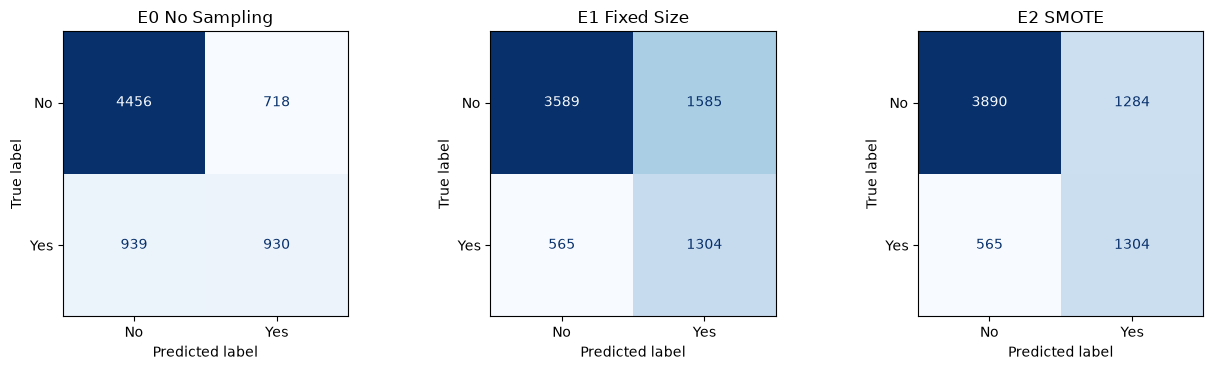

In [8]:
cm_table = pd.DataFrame({n: dict(TN=c[0,0], FP=c[0,1], FN=c[1,0], TP=c[1,1])
                         for n, c in cms.items()}).T
print(cm_table)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (name, cm) in zip(axes, cms.items()):
    ConfusionMatrixDisplay(cm, display_labels=["No", "Yes"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(name)
plt.tight_layout()
plt.show()

| Experiment | Accuracy | Precision positive | Recall positive | F1 positive | TN | FP | FN | TP |
|---|---|---|---|---|---|---|---|---|
| E0 No Sampling | 0.7647 | 0.5646 | 0.4976 | 0.5288 | 4456 | 718 | 939 | 930 |
| E1 Fixed Size | 0.6947 | 0.4512 | 0.6977 | 0.5477 | 3589 | 1585 | 565 | 1304 |
| E2 SMOTE | 0.7375 | 0.5054 | 0.6977 | 0.5854 | 3890 | 1284 | 565 | 1304 |

## Part D: Interpretation

6. Why is high Accuracy not enough? With IR = 2.77, a model that always says "No" already gets
5174/7043 = 73.5% accuracy while finding zero churners. Accuracy is dominated by the majority class,
so we must look at Precision, Recall and F1 of the minority (Yes) class.

7. False Negatives in E0: 939 of 1869 churners were missed (Recall = 0.498). The baseline is
biased toward the majority class: it catches only about half of the churners.

8. E1 vs E0: Recall rises from 0.498 to 0.698 (FN 939 to 565), but Precision drops from
0.565 to 0.451 (FP 718 to 1585). Training on a balanced 300/300 sample pushes the tree to predict
Yes more often, but it throws away most of the majority rows, so it makes many more false alarms.

9. E2 vs E1 (how training data is built): E1 removes records: it keeps only 300 + 300 = 600 real
rows per fold (undersampling, information is lost). E2 adds records: it keeps every real row and
creates new synthetic Yes rows by interpolating between a minority point and one of its k = 5 nearest
minority neighbours (on normalized features) until both classes are equal (~4139 each). These are new
points, not copies, and only the training fold receives them.

10. Largest FN reduction and the FP cost: E1 and E2 tie: both cut FN from 939 to 565 (-374).
The cost differs: E1 adds +867 FP (718 to 1585) while E2 adds only +566 FP (718 to 1284).
So E2 gets the same FN reduction with 301 fewer false alarms.

11. Final model: E2 SMOTE. It has the highest F1 (0.585), the same best Recall as E1 (0.698,
1304 of 1869 churners found, versus 930 in E0), and higher Precision than E1 (0.505 vs 0.451), i.e.
fewer FP (1284 vs 1585). E0 has the highest Accuracy but misses half the churners (939 FN), which is
the expensive error for a retention team. E2 gives the best Recall/Precision balance.